In [1]:
import time, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_auc_score,
                             RocCurveDisplay, ConfusionMatrixDisplay)
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
print("Setup OK")

Setup OK


In [2]:
iris = load_iris(as_frame=True)
X = iris.data.copy()
y = iris.target.copy()
target_names = list(iris.target_names)

df = X.copy()
df["species"] = y.map(dict(enumerate(target_names)))
print(f"Shape: {X.shape}  |  Features: {list(X.columns)}")
print(f"Classes: {target_names}")
df.head()

Shape: (150, 4)  |  Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: ['setosa', 'versicolor', 'virginica']


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 2. Exploratory Data Analysis (EDA)

In [3]:
print("=== Info ==="); print(df.info())
print("\n=== Describe ==="); print(df.describe().round(2))
print("\n=== Missing values ==="); print(df.isna().sum().sum(), "missing cells")
print("\n=== Class balance ==="); print(df["species"].value_counts())

=== Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB
None

=== Describe ===
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count             150.00            150.00             150.00   
mean                5.84              3.06               3.76   
std                 0.83              0.44               1.77   
min                 4.30              2.00               1.00   
25%                 5.10              2.80               1.60   
50%                 5.80              3.00               4.35   
75%              

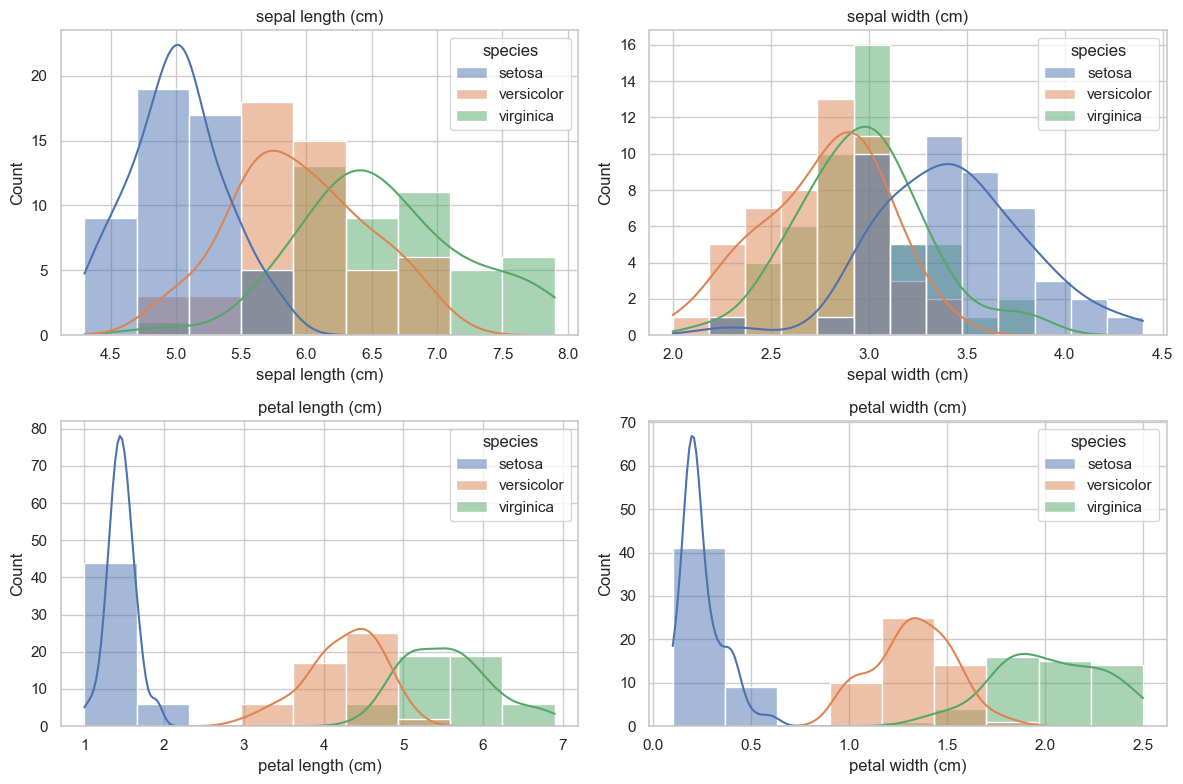

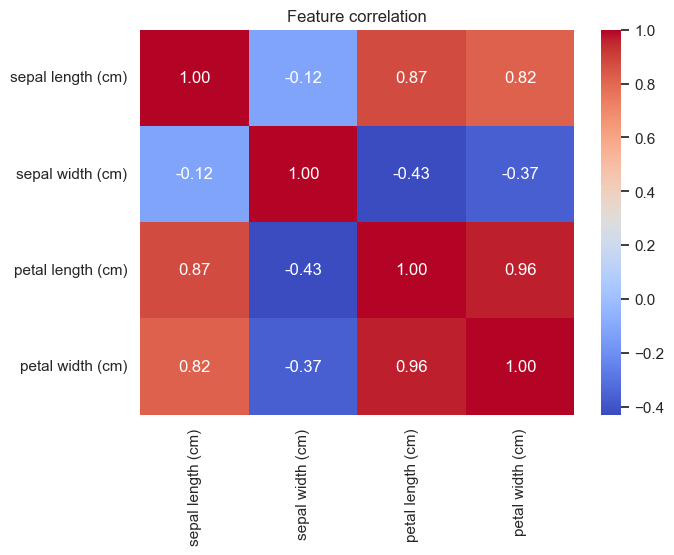

In [4]:
# Distributions per species + correlation matrix
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, X.columns):
    sns.histplot(data=df, x=col, hue="species", kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 5))
sns.heatmap(X.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature correlation"); plt.show()

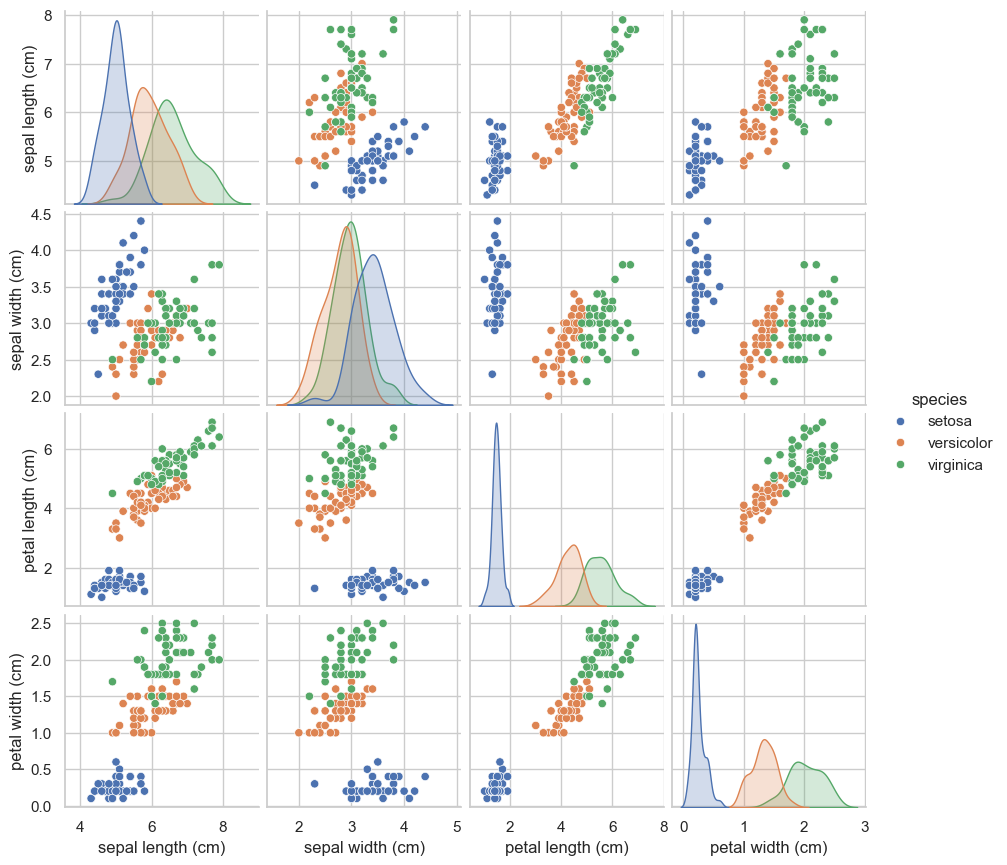

In [5]:
# Pairplot: petal measurements separate the species almost perfectly
sns.pairplot(df, hue="species", diag_kind="kde", height=2.2)
plt.show()

**EDA takeaways:** classes are balanced (50/50/50), no missing values, and petal
length/width separate `setosa` cleanly — so even simple models should score high.
That also means: don't trust accuracy alone on an easy dataset; compare F1, ROC-AUC
and cross-validation, and check *which* model is simplest/most robust.

## 3. Preprocess — split first, scale second (no data leakage)

- `stratify=y` keeps the 50/50/50 balance in both splits.
- `StandardScaler` is fit **only on the training set** (via a `Pipeline` for the
  final model, and manually here for the shared scaled arrays).
- Tree models don't need scaling, but scaling doesn't hurt them — using one shared
  scaled dataset keeps the comparison fair and simple.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit on TRAIN only
X_test_s  = scaler.transform(X_test)        # apply to test

print(f"Train: {X_train.shape}  Test: {X_test.shape}")
print("Train class counts:", np.bincount(y_train))
print("Test  class counts:", np.bincount(y_test))

Train: (120, 4)  Test: (30, 4)
Train class counts: [40 40 40]
Test  class counts: [10 10 10]


## 4. All classification models taught in class

Each entry is `(name, estimator)`. Optional models (XGBoost / LightGBM) are added
only if they import successfully, so the notebook never crashes on a missing library.

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              AdaBoostClassifier, GradientBoostingClassifier,
                              HistGradientBoostingClassifier)
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "KNN (k=5)":            KNeighborsClassifier(n_neighbors=5),
    "Decision Tree":        DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest":        RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    "Extra Trees":          ExtraTreesClassifier(n_estimators=200, random_state=RANDOM_STATE),
    "SVM (RBF)":            SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
    "SVM (Linear)":         SVC(kernel="linear", probability=True, random_state=RANDOM_STATE),
    "Naive Bayes":          GaussianNB(),
    "LDA":                  LinearDiscriminantAnalysis(),
    "QDA":                  QuadraticDiscriminantAnalysis(),
    "MLP (Neural Net)":     MLPClassifier(hidden_layer_sizes=(100,), max_iter=1000, random_state=RANDOM_STATE),
    "AdaBoost":             AdaBoostClassifier(random_state=RANDOM_STATE),
    "Gradient Boosting":    GradientBoostingClassifier(random_state=RANDOM_STATE),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}

# Optional boosters — added only when importable
try:
    from xgboost import XGBClassifier
    models["XGBoost"] = XGBClassifier(n_estimators=200, learning_rate=0.1,
                                      subsample=0.9, colsample_bytree=0.9,
                                      eval_metric="mlogloss", random_state=RANDOM_STATE)
    print("XGBoost: available")
except Exception as e:
    print("XGBoost: skipped ->", e)

try:
    from lightgbm import LGBMClassifier
    models["LightGBM"] = LGBMClassifier(n_estimators=200, verbose=-1, random_state=RANDOM_STATE)
    print("LightGBM: available")
except Exception as e:
    print("LightGBM: skipped ->", type(e).__name__)

print(f"\n{len(models)} models ready:", ", ".join(models))

XGBoost: skipped -> 
XGBoost Library (libxgboost.dylib) could not be loaded.
Likely causes:
  * OpenMP runtime is not installed
    - vcomp140.dll or libgomp-1.dll for Windows
    - libomp.dylib for Mac OSX
    - libgomp.so for Linux and other UNIX-like OSes
    Mac OSX users: Run `brew install libomp` to install OpenMP runtime.

  * You are running 32-bit Python on a 64-bit OS

Error message(s): ["dlopen(/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/xgboost/lib/libxgboost.dylib, 0x0006): Library not loaded: @rpath/libomp.dylib\n  Referenced from: <4ED95924-16D7-331E-8C6F-F25023ED13D1> /Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/xgboost/lib/libxgboost.dylib\n  Reason: tried: '/opt/anaconda3/lib/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/anaconda3/lib/libomp.dylib' (no such file), '/opt/anaconda3/lib/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/anaconda3/lib/libo

## 5. Train & evaluate every model with the same yardstick

For each model we record: test accuracy, weighted precision/recall/F1, ROC-AUC
(one-vs-rest, needs `predict_proba` — all models above provide it), 5-fold CV
accuracy on the training set, and wall-clock training time.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results, fitted = [], {}

for name, model in models.items():
    t0 = time.time()
    model.fit(X_train_s, y_train)
    train_time = time.time() - t0

    y_pred = model.predict(X_test_s)
    y_proba = model.predict_proba(X_test_s)
    cv_acc = cross_val_score(model, X_train_s, y_train, cv=cv, scoring="accuracy").mean()

    results.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "Recall":    recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "F1":        f1_score(y_test, y_pred, average="weighted", zero_division=0),
        "ROC-AUC":   roc_auc_score(y_test, y_proba, multi_class="ovr", average="weighted"),
        "CV Acc (5-fold)": cv_acc,
        "Train (s)": round(train_time, 3),
    })
    fitted[name] = model
    print(f"{name:24s} acc={results[-1]['Accuracy']:.3f}  F1={results[-1]['F1']:.3f}  "
          f"AUC={results[-1]['ROC-AUC']:.3f}  CV={cv_acc:.3f}")

results_df = pd.DataFrame(results).sort_values("F1", ascending=False).reset_index(drop=True)
results_df.round(4)

Logistic Regression      acc=0.933  F1=0.933  AUC=0.997  CV=0.958
KNN (k=5)                acc=0.933  F1=0.933  AUC=0.993  CV=0.958
Decision Tree            acc=0.933  F1=0.933  AUC=0.950  CV=0.950
Random Forest            acc=0.900  F1=0.900  AUC=0.993  CV=0.950
Extra Trees              acc=0.933  F1=0.933  AUC=0.993  CV=0.950
SVM (RBF)                acc=0.967  F1=0.967  AUC=0.997  CV=0.967
SVM (Linear)             acc=1.000  F1=1.000  AUC=1.000  CV=0.975
Naive Bayes              acc=0.967  F1=0.967  AUC=0.990  CV=0.950
LDA                      acc=1.000  F1=1.000  AUC=1.000  CV=0.975
QDA                      acc=1.000  F1=1.000  AUC=1.000  CV=0.967
MLP (Neural Net)         acc=0.967  F1=0.967  AUC=0.997  CV=0.950
AdaBoost                 acc=0.933  F1=0.933  AUC=0.975  CV=0.933
Gradient Boosting        acc=0.967  F1=0.967  AUC=0.997  CV=0.942
HistGradientBoosting     acc=0.900  F1=0.900  AUC=0.985  CV=0.950


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,CV Acc (5-fold),Train (s)
0,SVM (Linear),1.0000,1.0000,1.0000,1.0000,1.0000,0.9750,0.002
1,LDA,1.0000,1.0000,1.0000,1.0000,1.0000,0.9750,0.001
2,QDA,1.0000,1.0000,1.0000,1.0000,1.0000,0.9667,0.001
3,SVM (RBF),0.9667,0.9697,0.9667,0.9666,0.9967,0.9667,0.003
4,Naive Bayes,0.9667,0.9697,0.9667,0.9666,0.9900,0.9500,0.001
5,MLP (Neural Net),0.9667,0.9697,0.9667,0.9666,0.9967,0.9500,0.215
6,Gradient Boosting,0.9667,0.9697,0.9667,0.9666,0.9967,0.9417,0.239
7,Logistic Regression,0.9333,0.9333,0.9333,0.9333,0.9967,0.9583,0.009
8,Decision Tree,0.9333,0.9333,0.9333,0.9333,0.9500,0.9500,0.001
9,Extra Trees,0.9333,0.9333,0.9333,0.9333,0.9933,0.9500,0.160


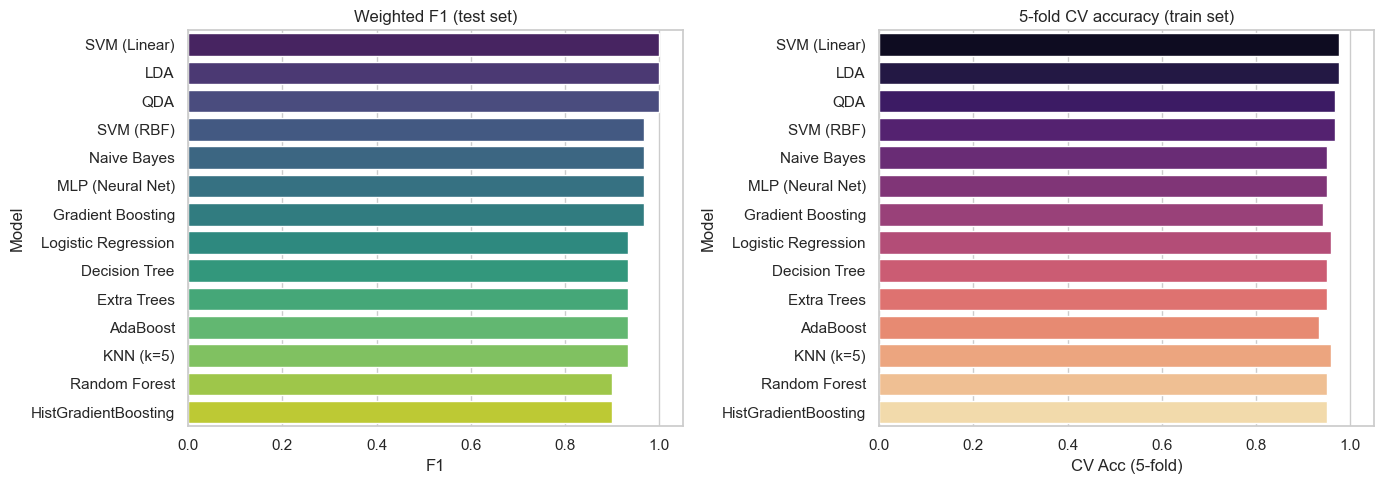

In [9]:
# Visual comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=results_df, y="Model", x="F1", ax=axes[0], palette="viridis")
axes[0].set_title("Weighted F1 (test set)"); axes[0].set_xlim(0, 1.05)

sns.barplot(data=results_df, y="Model", x="CV Acc (5-fold)", ax=axes[1], palette="magma")
axes[1].set_title("5-fold CV accuracy (train set)"); axes[1].set_xlim(0, 1.05)
plt.tight_layout(); plt.show()

## 6. Detailed report for the top-3 models

Accuracy alone hides *which* species get confused (usually `versicolor` vs `virginica`).
The confusion matrix + per-class report show exactly that.


SVM (Linear)
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      1.000     1.000     1.000        10
   virginica      1.000     1.000     1.000        10

    accuracy                          1.000        30
   macro avg      1.000     1.000     1.000        30
weighted avg      1.000     1.000     1.000        30



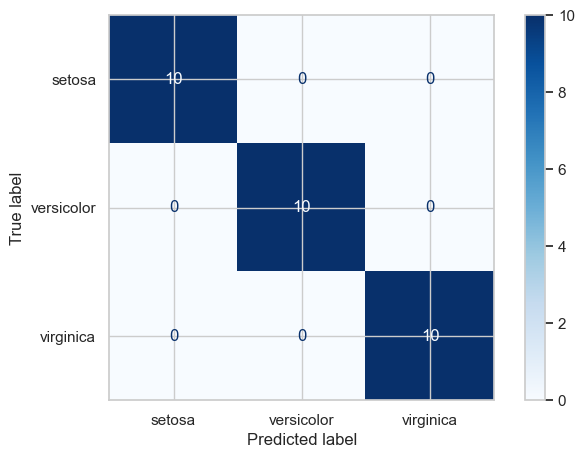

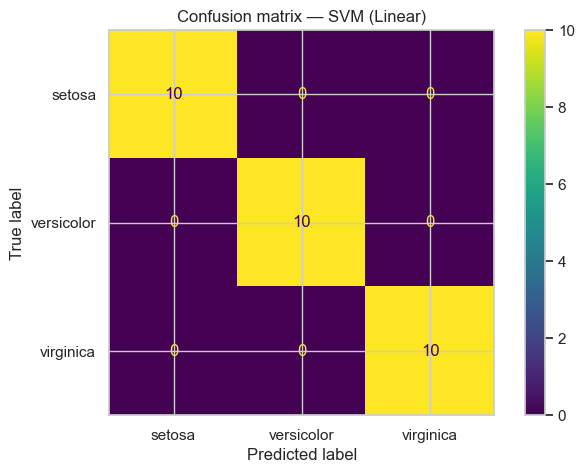


LDA
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      1.000     1.000     1.000        10
   virginica      1.000     1.000     1.000        10

    accuracy                          1.000        30
   macro avg      1.000     1.000     1.000        30
weighted avg      1.000     1.000     1.000        30



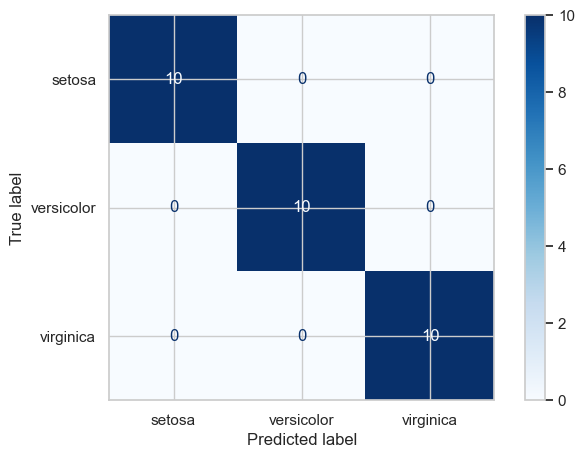

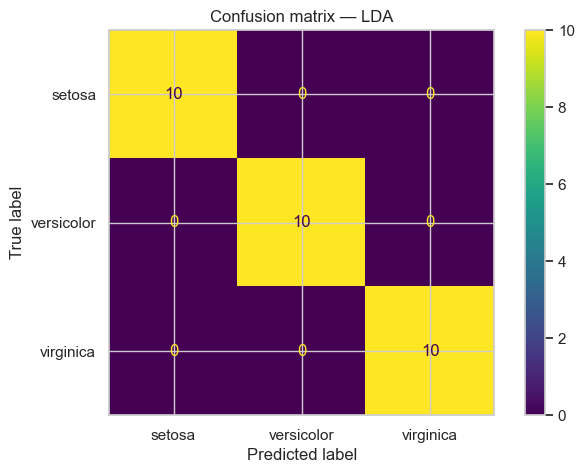


QDA
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      1.000     1.000     1.000        10
   virginica      1.000     1.000     1.000        10

    accuracy                          1.000        30
   macro avg      1.000     1.000     1.000        30
weighted avg      1.000     1.000     1.000        30



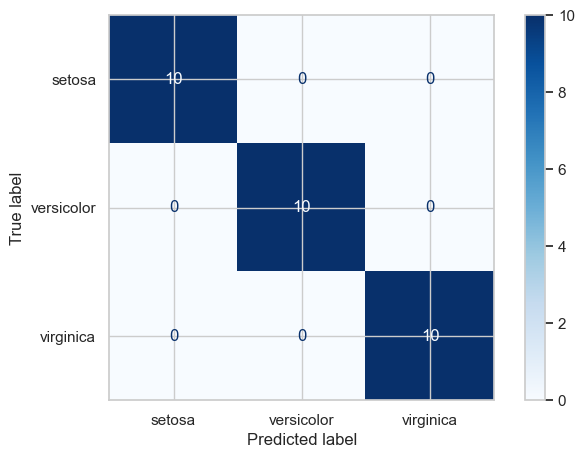

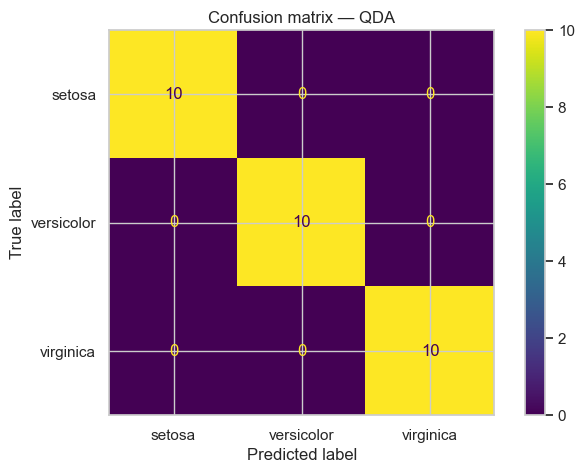

In [10]:
top3 = results_df.head(3)["Model"].tolist()
for name in top3:
    print(f"\n{'='*60}\n{name}\n{'='*60}")
    print(classification_report(y_test, fitted[name].predict(X_test_s),
                                target_names=target_names, digits=3))
    ConfusionMatrixDisplay.from_predictions(
        y_test, fitted[name].predict(X_test_s),
        display_labels=target_names, cmap="Blues").plot()
    plt.title(f"Confusion matrix — {name}"); plt.show()

## 7. Hyperparameter tuning — GridSearchCV on the strongest families

We tune the model families that usually win on tabular data. `GridSearchCV` uses the
same 5-fold CV and refits the winner on all training data. (Tuning *every* model
would be slow and rarely changes the ranking on Iris.)

In [11]:
grids = {
    "Logistic Regression": (LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        {"C": [0.1, 1, 10, 100], "penalty": ["l2"]}),
    "KNN (k=5)": (KNeighborsClassifier(),
        {"n_neighbors": [3, 5, 7, 11, 15], "weights": ["uniform", "distance"]}),
    "SVM (RBF)": (SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
        {"C": [0.1, 1, 10], "gamma": ["scale", "auto", 0.1, 1]}),
    "Random Forest": (RandomForestClassifier(random_state=RANDOM_STATE),
        {"n_estimators": [100, 300], "max_depth": [None, 3, 5], "min_samples_leaf": [1, 2]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=RANDOM_STATE),
        {"max_depth": [None, 3, 5, 7], "min_samples_leaf": [1, 2, 4]}),
}

tuned = {}
for name, (est, grid) in grids.items():
    search = GridSearchCV(est, grid, cv=cv, scoring="f1_weighted", n_jobs=-1)
    search.fit(X_train_s, y_train)
    tuned[name] = search.best_estimator_
    print(f"{name:22s} best={search.best_params_}  CV F1={search.best_score_:.4f}  "
          f"test acc={accuracy_score(y_test, search.predict(X_test_s)):.3f}")

Logistic Regression    best={'C': 10, 'penalty': 'l2'}  CV F1=0.9663  test acc=1.000
KNN (k=5)              best={'n_neighbors': 3, 'weights': 'uniform'}  CV F1=0.9665  test acc=0.933
SVM (RBF)              best={'C': 1, 'gamma': 0.1}  CV F1=0.9749  test acc=0.967
Random Forest          best={'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 100}  CV F1=0.9663  test acc=0.967
Decision Tree          best={'max_depth': None, 'min_samples_leaf': 2}  CV F1=0.9580  test acc=0.933


## 8. Pick the winner & save it

**Selection rule:** highest CV F1 first (most reliable estimate), then test F1,
then prefer the simpler/faster model. On Iris several models tie near 1.0 — in that
case pick the simplest one that generalises (often Logistic Regression or SVM).
The code below automates the choice and saves the winner **with its scaler** as a
single pipeline, so future predictions can't forget to scale.

In [12]:
# Re-score tuned models on the test set and rank everything together
final_rows = []
for name, est in {**fitted, **tuned}.items():
    y_pred = est.predict(X_test_s)
    final_rows.append({"Model": name, "Test F1": f1_score(y_test, y_pred, average="weighted"),
                       "Test Acc": accuracy_score(y_test, y_pred)})
final_df = pd.DataFrame(final_rows).sort_values("Test F1", ascending=False)
print(final_df.round(4).to_string(index=False))

best_name = final_df.iloc[0]["Model"]
best_est = tuned.get(best_name, fitted[best_name])
print(f"\nBest model: {best_name}")

# Wrap scaler + model into ONE pipeline and save it
best_pipeline = Pipeline([("scaler", StandardScaler()), ("model", best_est)])
best_pipeline.fit(X_train, y_train)   # raw (unscaled) features in, prediction out

import joblib
joblib.dump(best_pipeline, "best_iris_model.joblib")
print("Saved -> best_iris_model.joblib  (load with joblib.load(...))")

               Model  Test F1  Test Acc
 Logistic Regression   1.0000    1.0000
        SVM (Linear)   1.0000    1.0000
                 LDA   1.0000    1.0000
                 QDA   1.0000    1.0000
       Random Forest   0.9666    0.9667
           SVM (RBF)   0.9666    0.9667
         Naive Bayes   0.9666    0.9667
    MLP (Neural Net)   0.9666    0.9667
   Gradient Boosting   0.9666    0.9667
       Decision Tree   0.9333    0.9333
         Extra Trees   0.9333    0.9333
            AdaBoost   0.9333    0.9333
           KNN (k=5)   0.9327    0.9333
HistGradientBoosting   0.8997    0.9000

Best model: Logistic Regression
Saved -> best_iris_model.joblib  (load with joblib.load(...))


## 9. Inspect the winner — ROC curves & feature importance (where available)

In [13]:
y_proba = best_pipeline.predict_proba(X_test)
RocCurveDisplay.from_predictions(y_test, y_proba, labels=[0, 1, 2],
                                 name="ROC — best model", plot_chance_level=True)
plt.title(f"ROC curves — {best_name}"); plt.show()

# Feature importance / coefficients, if the model exposes them
model = best_pipeline.named_steps["model"]
if hasattr(model, "feature_importances_"):
    imp = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
    print("Feature importances:"); print(imp.round(4))
    imp.plot.barh(); plt.title("Feature importance"); plt.tight_layout(); plt.show()
elif hasattr(model, "coef_"):
    coef = pd.DataFrame(model.coef_, index=target_names, columns=X.columns)
    print("Coefficients (per class):"); print(coef.round(3))
    coef.T.plot.bar(figsize=(10, 5)); plt.title("Logistic Regression coefficients")
    plt.tight_layout(); plt.show()
else:
    print(f"{best_name} exposes neither feature_importances_ nor coef_ — skipping.")

ValueError: The target y is not binary. Got multiclass type of target.

## 10. Predict on new samples

The saved pipeline takes **raw** measurements — no manual scaling needed.

In [ ]:
import joblib
model = joblib.load("best_iris_model.joblib")

# Example: 3 unseen flowers (sepal length, sepal width, petal length, petal width)
new_flowers = pd.DataFrame([
    [5.1, 3.5, 1.4, 0.2],   # classic setosa-like
    [6.0, 2.9, 4.5, 1.5],   # versicolor-like
    [6.3, 3.3, 6.0, 2.5],   # virginica-like
], columns=X.columns)

preds  = model.predict(new_flowers)
probas = model.predict_proba(new_flowers)
for i, (row, p, proba) in enumerate(zip(new_flowers.itertuples(index=False), preds, probas)):
    print(f"Sample {i+1}: {list(row)} -> {target_names[p]} "
          f"(confidence {proba.max():.1%}, all probs {np.round(proba, 3)})")

## 11. Conclusion — which model should you actually use?

| Situation | Good default |
|---|---|
| Interpretable baseline, small clean data | **Logistic Regression** |
| No assumptions, quick check | **KNN** (needs scaling) |
| Rules you can read / feature importance | **Decision Tree** (prune it!) |
| Best all-rounder on tabular data | **Random Forest / Extra Trees** |
| Small data, non-linear boundary | **SVM (RBF)** |
| Tiny data, probabilistic answer | **Naive Bayes** |
| Gaussian-ish classes, fast & stable | **LDA / QDA** |
| Non-linear patterns, lots of data | **MLP** (needs scaling + tuning) |
| Top accuracy on tabular data | **Gradient Boosting / XGBoost / LightGBM** |

**On Iris specifically:** almost every model reaches ~0.93–1.00 accuracy because the
classes are nearly separable. The honest conclusion is not "model X wins" but
"the problem is easy — choose the simplest model with the best CV score, and
re-check on harder/real data before trusting it."

**Common pitfalls this notebook avoided:**
- Scaling fit on the whole dataset (leakage) → scaler fit on train only.
- Reporting accuracy only → F1, ROC-AUC, CV and confusion matrices.
- Tuning on the test set → tuning with CV on train, test used once at the end.

## Appendix — Reuse this notebook with your own dataset

1. Replace the data-loading cell (Section 1) with:
   ```python
   df = pd.read_csv("your_data.csv")
   TARGET = "your_target_column"          # <-- change this
   X = df.drop(columns=[TARGET])
   y = LabelEncoder().fit_transform(df[TARGET])   # handles string labels
   ```
2. Keep everything else the same — models, evaluation, tuning and saving all work
   for any tabular classification dataset (binary or multi-class).
3. For binary problems, `roc_auc_score(..., multi_class="ovr")` still works, and
   `RocCurveDisplay` in Section 9 will draw a single curve.